# Tarea 2 · Parte 2 — Evaluación (CER/WER), extracción estructurada con LLM y comparación de modelos

Reglas que sigo en este notebook:
1. La muestra de evaluación (10 documentos, 10 clips) se elige **con semilla fija antes de correr cualquier modelo alternativo** y se usa la misma para todos.
2. Las configuraciones de todos los modelos se fijan en la celda de configuración; **no se ajustan** después de ver las métricas.
3. Referencia y salida automática se normalizan con el mismo criterio (`voz.normalizar`: minúsculas, sin tildes ni puntuación) y en WER se eliminan las marcas `[HABLANTE_n]`.

In [1]:
import json, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import jiwer
import voz
# Gráficos interactivos en Jupyter + copia PNG estática para que se vean en GitHub (kaleido usa Chrome/Edge)
import os
os.environ.setdefault("BROWSER_PATH", "C:/Program Files (x86)/Microsoft/Edge/Application/msedge.exe")
pio.renderers.default = "notebook_connected+png"
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 100)

DATOS = Path("datos"); RAW = DATOS / "raw"; CACHE = RAW / "cache"
docs = pd.read_csv(DATOS / "documentos.csv")
aud = pd.read_csv(DATOS / "transcripciones.csv")
man_aud = pd.read_csv(RAW / "audio" / "manifiesto.csv")

CONFIG = {
    "ocr_base": "PaddleOCR 3 PP-OCRv5 mobile (latin) lang=es (sin personalización)",
    "ocr_alt": "EasyOCR 1.7 lang=['es'] paragraph=True",
    "asr_base": "faster-whisper small int8 CPU, VAD on, greedy",
    "asr_alt": "wav2vec2-large-xlsr-53-spanish (CTC, greedy) CPU",
    "llm": "Qwen2.5-1.5B-Instruct Q4_K_M (llama.cpp, CPU, temperatura 0)",
}
CONFIG

{'ocr_base': 'PaddleOCR 3 PP-OCRv5 mobile (latin) lang=es (sin personalización)',
 'ocr_alt': "EasyOCR 1.7 lang=['es'] paragraph=True",
 'asr_base': 'faster-whisper small int8 CPU, VAD on, greedy',
 'asr_alt': 'wav2vec2-large-xlsr-53-spanish (CTC, greedy) CPU',
 'llm': 'Qwen2.5-1.5B-Instruct Q4_K_M (llama.cpp, CPU, temperatura 0)'}

## 1. Muestra de evaluación (sin nuevos datos)
- **Documentos:** 4 impresos + 3 fotos + 3 manuscritos, sorteados con semilla 2026 entre los 25 de la Parte 1.
- **Audio:** 10 clips de la Parte 1 con **transcripción humana disponible**: los clips de OpenSLR 73 traen la transcripción manual de cada enunciado
  hecha y validada por anotadores humanos (no es una salida automática). Se sortean 5 de voces femeninas y 5 masculinas (hablantes distintos).
  Las entrevistas de calle de Commons no tienen referencia publicada; se analizan como caso difícil en la sección 5.
- Las referencias de documentos están en `datos/referencias_documentos.json` (transcripción manual de la imagen, conservando ortografía original).

In [2]:
rng = random.Random(2026)
muestra_doc = []
for tipo, k in [("impreso", 4), ("foto", 3), ("manuscrito", 3)]:
    muestra_doc += sorted(rng.sample(sorted(docs[docs.tipo == tipo].id), k))
openslr = man_aud[man_aud.tipo == "openslr73"]
fem = sorted(openslr[openslr.titulo.str.contains("female")].id)
mas = sorted(openslr[~openslr.titulo.str.contains("female")].id)
muestra_aud = sorted(rng.sample(fem, 5) + rng.sample(mas, 5))
print("Documentos:", muestra_doc)
print("Clips:", muestra_aud)

Documentos: ['doc_002', 'doc_003', 'doc_005', 'doc_006', 'doc_011', 'doc_014', 'doc_017', 'doc_025', 'doc_026', 'doc_027']
Clips: ['clip_011', 'clip_014', 'clip_015', 'clip_016', 'clip_017', 'clip_018', 'clip_019', 'clip_022', 'clip_023', 'clip_024']


In [3]:
ref_doc = json.loads((DATOS / "referencias_documentos.json").read_text(encoding="utf-8"))
ref_aud = man_aud.set_index("id").texto_referencia_fuente.to_dict()
docs["texto_referencia"] = docs.id.map(lambda i: ref_doc.get(i, "") if i in muestra_doc else "")
aud["texto_referencia"] = aud.id.map(lambda i: ref_aud.get(i, "") if i in muestra_aud else "")
docs.to_csv(DATOS / "documentos.csv", index=False)
aud.to_csv(DATOS / "transcripciones.csv", index=False)
print("Referencias cargadas:", (docs.texto_referencia.fillna("") != "").sum(), "documentos |",
      (aud.texto_referencia.fillna("") != "").sum(), "clips")

Referencias cargadas: 10 documentos | 10 clips


## 2. Línea base sin ajuste
- OCR: salida cruda de PaddleOCR de la Parte 1 (mismo modelo, sin cambios).
- ASR: faster-whisper `small` en CPU (salida de la Parte 1; el tiempo de proceso medido allí da el factor de tiempo real, RTF).

In [4]:
def cer(ref, hip):
    r, h = voz.normalizar(ref), voz.normalizar(hip)
    return jiwer.cer(r, h) if r else np.nan

def wer(ref, hip):
    r, h = voz.normalizar(ref), voz.normalizar(hip)
    return jiwer.wer(r, h) if r else np.nan

def leer_ocr_paddle(i):
    return json.loads((RAW / "documentos" / "ocr_paddle" / f"{i}.json").read_text(encoding="utf-8"))

ev_doc = docs[docs.id.isin(muestra_doc)].set_index("id")
filas_doc = []
for i in muestra_doc:
    d = leer_ocr_paddle(i)
    filas_doc.append({"id": i, "modelo": "PaddleOCR (base)", "cer": cer(ref_doc[i], d["texto"]), "segundos": d["segundos"], "hipotesis": d["texto"]})

filas_aud = []
for i in muestra_aud:
    d = json.loads((CACHE / f"asr_{i}.json").read_text(encoding="utf-8"))
    filas_aud.append({"id": i, "modelo": "faster-whisper small (base)", "wer": wer(ref_aud[i], d["texto_asr_crudo"]),
                      "rtf": d["seg_proceso"] / d["duracion_seg"], "hipotesis": d["texto_asr_crudo"]})
base_doc, base_aud = pd.DataFrame(filas_doc), pd.DataFrame(filas_aud)
print(f"Línea base  CER PaddleOCR = {base_doc.cer.mean():.3f}   WER faster-whisper small = {base_aud.wer.mean():.3f}")
base_doc.merge(docs[["id", "tipo"]]).groupby("tipo").cer.mean().round(3)

Línea base  CER PaddleOCR = 0.347   WER faster-whisper small = 0.033

tipo
foto          0.320
impreso       0.220
manuscrito    0.543
Name: cer, dtype: float64

## 3. Modelos alternativos sobre las mismas muestras
### 3.1 OCR alternativo: EasyOCR
Justificación: Tesseract requiere instalar un binario del sistema (no disponible sin permisos de administrador en mi laptop);
EasyOCR es un OCR abierto con otra arquitectura (detector CRAFT + reconocedor CRNN), instalable con `pip` y con modelo latino que cubre el español.

In [5]:
import easyocr
lector = easyocr.Reader(["es"], gpu=False, verbose=False)
for i in muestra_doc:
    cache = CACHE / f"easyocr_{i}.json"
    if cache.exists():
        d = json.loads(cache.read_text(encoding="utf-8"))
    else:
        t0 = time.perf_counter()
        texto = "\n".join(lector.readtext(ev_doc.loc[i, "archivo"], detail=0, paragraph=True))
        d = {"texto": texto, "segundos": time.perf_counter() - t0}
        cache.write_text(json.dumps(d, ensure_ascii=False), encoding="utf-8")
    filas_doc.append({"id": i, "modelo": "EasyOCR (alternativo)", "cer": cer(ref_doc[i], d["texto"]), "segundos": d["segundos"], "hipotesis": d["texto"]})

### 3.2 ASR alternativo: wav2vec2 XLSR-53 español (familia CTC de MMS)
Justificación: Qwen3-ASR y Parakeet no corren de forma práctica en CPU de 4 núcleos y 10 GB de RAM; MMS-1B ocupa ~4 GB en fp32.
`jonatasgrosman/wav2vec2-large-xlsr-53-spanish` es un modelo CTC de 300 M parámetros (misma base wav2vec2/XLS-R que MMS) afinado en Common Voice español.
Se procesa en ventanas de 20 s sobre el audio a 16 kHz.

In [6]:
import torch, soundfile as sf
from transformers import Wav2Vec2ForCTC, Wav2Vec2Processor
torch.set_num_threads(4)
W2V = "jonatasgrosman/wav2vec2-large-xlsr-53-spanish"
proc = Wav2Vec2Processor.from_pretrained(W2V)
w2v = Wav2Vec2ForCTC.from_pretrained(W2V).eval()

def asr_w2v(ruta):
    y, sr = sf.read(ruta)
    t0 = time.perf_counter()
    trozos = []
    for ini in range(0, len(y), 20 * sr):
        x = proc(y[ini: ini + 20 * sr], sampling_rate=sr, return_tensors="pt").input_values
        with torch.no_grad():
            ids = w2v(x).logits.argmax(-1)
        trozos.append(proc.batch_decode(ids)[0])
    return " ".join(trozos), time.perf_counter() - t0, len(y) / sr

ev_aud = aud.set_index("id")
for i in muestra_aud:
    cache = CACHE / f"w2v_{i}.json"
    if cache.exists():
        d = json.loads(cache.read_text(encoding="utf-8"))
    else:
        texto, seg, dur = asr_w2v(ev_aud.loc[i, "archivo_audio"])
        d = {"texto": texto, "segundos": seg, "duracion": dur}
        cache.write_text(json.dumps(d, ensure_ascii=False), encoding="utf-8")
    filas_aud.append({"id": i, "modelo": "wav2vec2-xlsr-es (alternativo)", "wer": wer(ref_aud[i], d["texto"]),
                      "rtf": d["segundos"] / d["duracion"], "hipotesis": d["texto"]})

## 4. Métricas finales sobre la muestra de evaluación

In [7]:
comp_doc = pd.DataFrame(filas_doc).merge(docs[["id", "tipo"]], on="id")
comp_aud = pd.DataFrame(filas_aud)
comp_doc.to_csv(DATOS / "comparacion_ocr.csv", index=False)
comp_aud.to_csv(DATOS / "comparacion_asr.csv", index=False)

tabla_doc = comp_doc.groupby("modelo").agg(CER=("cer", "mean"), seg_por_doc=("segundos", "mean")).round(3)
tabla_tipo = comp_doc.pivot_table(index="modelo", columns="tipo", values="cer", aggfunc="mean").round(3)
tabla_aud = comp_aud.groupby("modelo").agg(WER=("wer", "mean"), RTF=("rtf", "mean")).round(3)
display(tabla_doc.join(tabla_tipo.add_prefix("CER_")))
display(tabla_aud)

,CER,seg_por_doc,CER_foto,CER_impreso,CER_manuscrito
modelo,,,,,
EasyOCR (alternativo),0.412,94.112,0.364,0.254,0.673
PaddleOCR (base),0.347,58.974,0.320,0.220,0.543


,WER,RTF
modelo,,
faster-whisper small (base),0.033,1.209
wav2vec2-xlsr-es (alternativo),0.227,2.541


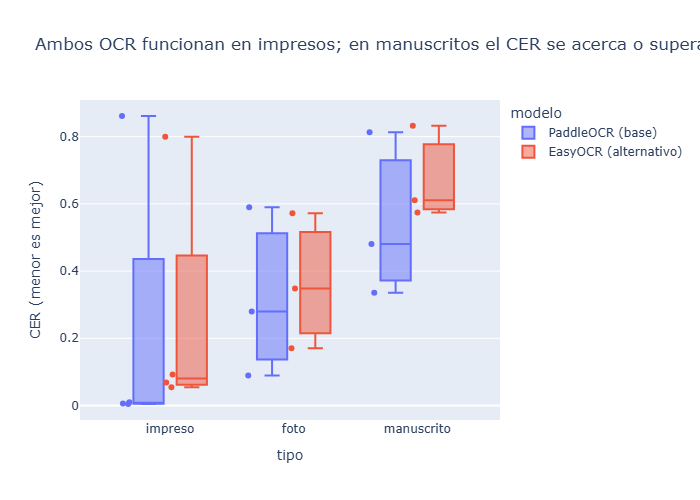

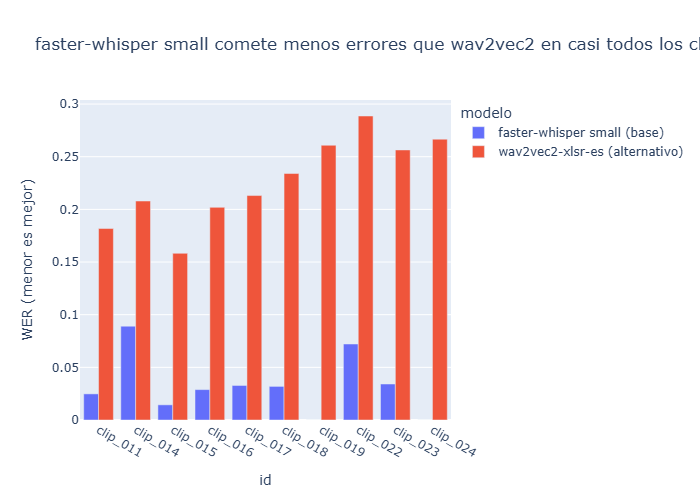

In [8]:
fig = px.box(comp_doc, x="tipo", y="cer", color="modelo", points="all",
             title="Ambos OCR funcionan en impresos; en manuscritos el CER se acerca o supera 1 (texto casi inservible)",
             labels={"cer": "CER (menor es mejor)"})
fig.show()
fig = px.bar(comp_aud, x="id", y="wer", color="modelo", barmode="group",
             title="faster-whisper small comete menos errores que wav2vec2 en casi todos los clips",
             labels={"wer": "WER (menor es mejor)"})
fig.show()

## 5. Extracción estructurada con LLM local
Prompt estructurado con salida JSON forzada por gramática (`response_format` JSON de llama.cpp), temperatura 0. Se pide `null` para datos ausentes.

In [9]:
from llama_cpp import Llama
# Pesos descargados de https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct-GGUF (no versionados).
# Se cargan solo si falta alguna extracción en caché (datos/raw/cache/llm_*.json).
llm = None

def cargar_llm():
    global llm
    if llm is None:
        llm = Llama(model_path="modelos/qwen2.5-1.5b-instruct-q4_k_m.gguf", n_ctx=4096, n_threads=4, verbose=False)
    return llm

PROMPT_DOC = """Eres un archivista. Lee el texto OCR de un documento peruano (puede tener errores de OCR) y devuelve SOLO un JSON con estas claves:
"modalidad": "documento", "tema": frase corta, "resumen": una oración, "emisor": quién emite el documento o null,
"fecha": fecha que aparezca literalmente en el texto o null, "monto": monto de dinero que aparezca literalmente o null.
Si un dato no aparece en el texto, usa null. No inventes información.

TEXTO OCR:
{texto}"""
PROMPT_AUD = """Lee la transcripción automática de un audio en español peruano y devuelve SOLO un JSON con estas claves:
"modalidad": "audio", "tema": frase corta, "resumen": una oración, "numero_hablantes": número de hablantes distintos si hay marcas [HABLANTE_n], si no null,
"citas_clave": lista de máximo 2 frases copiadas literalmente de la transcripción.
No inventes información.

TRANSCRIPCIÓN:
{texto}"""

def extraer(texto, plantilla):
    texto = (texto or "")[:2500]  # límite por costo en CPU (contexto y latencia)
    out = cargar_llm().create_chat_completion(
        messages=[{"role": "user", "content": plantilla.format(texto=texto)}],
        response_format={"type": "json_object"}, temperature=0, max_tokens=250)
    try:
        return json.loads(out["choices"][0]["message"]["content"])
    except json.JSONDecodeError:
        return {"error": "json_invalido", "crudo": out["choices"][0]["message"]["content"]}

filas = []
for modalidad, df, col, plantilla in [("documento", docs, "texto_ocr", PROMPT_DOC), ("audio", aud, "texto_asr", PROMPT_AUD)]:
    for r in df.itertuples():
        cache = CACHE / f"llm_{r.id}.json"
        if cache.exists():
            campos = json.loads(cache.read_text(encoding="utf-8"))
        else:
            campos = extraer(getattr(r, col), plantilla)
            cache.write_text(json.dumps(campos, ensure_ascii=False), encoding="utf-8")
        filas.append({"id": r.id, "modalidad": modalidad, "campos_json": json.dumps(campos, ensure_ascii=False),
                      "modelo_llm": CONFIG["llm"], "fecha": "2026-10-25"})
extraccion = pd.DataFrame(filas)
extraccion.to_csv(DATOS / "extraccion_llm.csv", index=False)
print(extraccion.shape)
extraccion.head(6)

(49, 5)


,id,modalidad,campos_json,modelo_llm,fecha
0,doc_001,documento,"{""modalidad"": ""documento"", ""tema"": ""Constitución Política"", ""resumen"": ""Constitución Política de...","Qwen2.5-1.5B-Instruct Q4_K_M (llama.cpp, CPU, temperatura 0)",2026-10-25
1,doc_002,documento,"{""modalidad"": ""documento"", ""tema"": ""derechos y deberes del senador"", ""resumen"": ""El artículo 22 ...","Qwen2.5-1.5B-Instruct Q4_K_M (llama.cpp, CPU, temperatura 0)",2026-10-25
2,doc_003,documento,"{""modalidad"": ""documento"", ""tema"": ""TOM3TZ/0"", ""resumen"": ""UNRTNO"", ""emisor"": null, ""fecha"": nul...","Qwen2.5-1.5B-Instruct Q4_K_M (llama.cpp, CPU, temperatura 0)",2026-10-25
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""Forma de Gobierno"", ""resumen"": ""El Gobierno de la República ...","Qwen2.5-1.5B-Instruct Q4_K_M (llama.cpp, CPU, temperatura 0)",2026-10-25
4,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""Constitución política del Perú"", ""resumen"": ""La Constitución...","Qwen2.5-1.5B-Instruct Q4_K_M (llama.cpp, CPU, temperatura 0)",2026-10-25
5,doc_006,documento,"{""modalidad"": ""documento"", ""tema"": ""Funciones públicas y Poder Legislativo"", ""resumen"": ""El Pode...","Qwen2.5-1.5B-Instruct Q4_K_M (llama.cpp, CPU, temperatura 0)",2026-10-25


## 6. Auditoría humana de 20 extracciones al azar (10 documentos + 10 audios)
**Criterios de corrección (fijados antes de revisar):** una extracción es *completamente correcta* si
(a) el JSON es válido y tiene las claves pedidas; (b) `tema` y `resumen` son fieles al texto; (c) los campos factuales
(`emisor`, `fecha`, `monto`, `numero_hablantes`, `citas_clave`) son correctos **o** `null` cuando el dato no aparece; (d) no hay datos inventados.
Un solo campo erróneo o inventado ⇒ incorrecta. La revisión se registró en `datos/auditoria_llm.csv` comparando cada JSON con el texto fuente y la imagen/audio.

In [10]:
rng = random.Random(20)
muestra_auditoria = sorted(rng.sample(sorted(docs.id), 10)) + sorted(rng.sample(sorted(aud.id), 10))
auditoria = pd.read_csv(DATOS / "auditoria_llm.csv")
assert sorted(auditoria.id) == sorted(muestra_auditoria), "La auditoría debe cubrir exactamente la muestra sorteada"
ok = int(auditoria.correcto.sum())
print(f"Extracciones completamente correctas: {ok}/20 = {ok/20:.0%}")
display(auditoria.groupby("modalidad").correcto.agg(["sum", "count"]))
print("Tipos de error:"); display(auditoria[~auditoria.correcto].tipo_error.value_counts())
display(auditoria[~auditoria.correcto][["id", "tipo_error", "nota"]])

Extracciones completamente correctas: 4/20 = 20%


,sum,count
modalidad,,
audio,2,10
documento,2,10


Tipos de error:


tipo_error
dato_inventado    6
campo_erroneo     5
resumen_infiel    3
formato           2
Name: count, dtype: int64

,id,tipo_error,nota
0,doc_001,dato_inventado,Inventa 'República del Darien' a partir del OCR deformado de 'República Peruana'; emisor como ca...
1,doc_004,campo_erroneo,fecha='3' (toma el número de página como fecha); tema y resumen correctos
4,doc_010,dato_inventado,"OCR vacío: el LLM rellena con marcadores ('Tema del documento', 'Fecha del documento') en lugar ..."
5,doc_012,campo_erroneo,Nombre mal reconstruido (Iturriaga y Aguilar por Iturregui y Aguilarte) y lo pone como emisor; r...
6,doc_015,resumen_infiel,Dice que el alcalde 'solicita' la obra; es una placa conmemorativa de una obra ya ejecutada
7,doc_023,dato_inventado,Llama al libro de bautismos 'obra de arte' y da fecha 1591 a partir del OCR erróneo
8,doc_024,campo_erroneo,emisor='Juan' y fecha='92' tomados de ruido OCR del manuscrito
9,doc_026,dato_inventado,fecha='2023' no aparece en el texto; tema/resumen copian ruido del OCR
10,clip_003,resumen_infiel,Resume como 'crisis de comunicación'; la conversación trata del desempeño de la selección peruana
11,clip_004,campo_erroneo,numero_hablantes=3 cuando el texto tiene 4 marcas; tema 'Música' cuando es la marcha del orgullo


## 7. Casos difíciles

In [11]:
dificil_doc = comp_doc[comp_doc.tipo == "manuscrito"].pivot_table(index="id", columns="modelo", values="cer").round(2)
display(dificil_doc)
calle = aud[aud.fuente.str.contains("Commons")][["id", "duracion_seg", "n_hablantes", "texto_asr"]]
calle = calle.assign(texto_asr=calle.texto_asr.str[:160])
display(calle)

modelo,EasyOCR (alternativo),PaddleOCR (base)
id,,
doc_025,0.61,0.34
doc_026,0.83,0.81
doc_027,0.57,0.48


,id,duracion_seg,n_hablantes,texto_asr
0,clip_001,136.3,4,"[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme su opinión ..."
1,clip_002,189.0,4,"[HABLANTE_1] Buenos días profesor y compañeros, hoy estoy cerca de aquí por mi casa y voy a hace..."
2,clip_003,29.9,3,"[HABLANTE_1] Normal, pero no resultaba nada. [HABLANTE_2] Pero como lo ves? Como ves a Perú ahor..."
3,clip_004,54.3,4,"[HABLANTE_1] Sí, dejólo ya. Así está la banda. [HABLANTE_2] ¿Qué ayuda? [HABLANTE_3] Ya está la ..."
4,clip_005,95.0,4,"[HABLANTE_1] Ahora, mi nombre es [PERSONA_12], pero si eras no [PERSONA_11], ahora me voy a pres..."
5,clip_006,77.4,4,[HABLANTE_1] ¿Sabes así? [HABLANTE_2] Sí. [HABLANTE_3] Yo soy [PERSONA_14] [PERSONA_11] de la Fa...
6,clip_007,98.3,2,"[HABLANTE_1] ¿Qué se llama? [HABLANTE_2] Chuyas, ¿verdad? [HABLANTE_1] ¿Usted es chuyas? [HABLAN..."
7,clip_008,250.6,4,"[HABLANTE_1] Bueno, hola, estamos en la San Martín, entre Fritas Patreas, 28 de julio. Entonces,..."
8,clip_009,196.0,2,"[HABLANTE_1] Buenas noches, primeramente es mi nombre [PERSONA_16], soy estudiante de la Univers..."
9,clip_010,96.1,3,"[HABLANTE_1] Nos encontramos aquí con el señor [PERSONA_18]. Señor [PERSONA_19], esta entrevista..."


## 8. Tabla comparativa y decisión

In [12]:
tabla = pd.concat([
    tabla_doc.reset_index().rename(columns={"CER": "error", "seg_por_doc": "costo"}).assign(modalidad="documentos", metrica="CER", unidad_costo="s/documento (CPU)"),
    tabla_aud.reset_index().rename(columns={"WER": "error", "RTF": "costo"}).assign(modalidad="audio", metrica="WER", unidad_costo="RTF (CPU)"),
])[["modalidad", "modelo", "metrica", "error", "costo", "unidad_costo"]].round(3)
display(tabla)

mejor_ocr = tabla_doc.CER.idxmin(); mejor_asr = tabla_aud.WER.idxmin()
metricas = {
    "cer_base": round(float(tabla_doc.loc["PaddleOCR (base)", "CER"]), 3),
    "wer_base": round(float(tabla_aud.loc["faster-whisper small (base)", "WER"]), 3),
    "cer_elegido": round(float(tabla_doc.CER.min()), 3), "modelo_ocr_elegido": mejor_ocr,
    "wer_elegido": round(float(tabla_aud.WER.min()), 3), "modelo_asr_elegido": mejor_asr,
    "auditoria_ok": ok, "auditoria_n": 20,
    "tabla_comparativa": tabla.to_dict("records"),
}
(DATOS / "metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"Resultados Test: WER: {metricas['wer_elegido']:.2f} | CER: {metricas['cer_elegido']:.2f} | Acuerdo LLM-Humano: {ok}/20")

,modalidad,modelo,metrica,error,costo,unidad_costo
0,documentos,EasyOCR (alternativo),CER,0.412,94.112,s/documento (CPU)
1,documentos,PaddleOCR (base),CER,0.347,58.974,s/documento (CPU)
0,audio,faster-whisper small (base),WER,0.033,1.209,RTF (CPU)
1,audio,wav2vec2-xlsr-es (alternativo),WER,0.227,2.541,RTF (CPU)


Resultados Test: WER: 0.03 | CER: 0.35 | Acuerdo LLM-Humano: 4/20


## 9. Decisión y reflexión

**Decisión para un entorno real (CPU, sin GPU):**
- **Documentos → PaddleOCR (PP-OCRv5 mobile, reconocedor latino).** Menor CER en los 10 documentos (0,35 vs 0,41) y en los tres tipos, y además ~40 % más rápido
  por documento que EasyOCR en la misma laptop. EasyOCR no aporta ventaja en ningún tipo.
- **Audio → faster-whisper `small` (int8, VAD).** WER 0,03 vs 0,23 de wav2vec2 en los mismos 10 clips y menor RTF. wav2vec2 (CTC sin modelo de lenguaje)
  produce errores ortográficos fonéticos (b/v, s/z, palabras partidas) y no puntúa, lo que además empeora la extracción posterior con el LLM.
- **LLM → Qwen2.5-1.5B solo como borrador.** 4/20 extracciones completamente correctas: no es utilizable sin revisión humana. Para producción haría falta un modelo
  más grande (7B+ o API) y validación de campos (p. ej., rechazar fechas que no sean años/fechas reales y citas que no estén literalmente en el texto).

**Reflexión por tipo de documento:**
- *Impresos* (CER 0,22 con PaddleOCR, pero ≈0,01 en las páginas de texto corrido): el mejor caso. El promedio sube solo por la portada desvaída de 1856 (doc_003),
  donde el OCR casi no detecta texto: el problema es el contraste, no la tipografía.
- *Fotos* (CER 0,32): bien en placas con letras grandes y poca perspectiva (doc_011: 0,09); mal en el cartel bilingüe de Huaca Melgarejo (0,59), porque el OCR lee por líneas
  cruzando las dos columnas (español/inglés) y el orden de lectura no coincide con la referencia; y en relieves metálicos con reflejos (doc_017: 0,28).
- *Manuscritos* (CER 0,54): el peor caso, como se esperaba. PaddleOCR no tiene un modelo de escritura a mano; acierta parcialmente en la partida de 1792 con letra
  regular (0,34) y fracasa en el Acta de la Independencia (0,81), con letra del s. XIX, abreviaturas y decenas de firmas superpuestas.

**Reflexión por tipo de audio:**
- *Habla leída de OpenSLR 73* (WER 0,03): casi perfecta; los errores son nombres propios y palabras poco frecuentes ("sarsamora", "Ruflo" por Rulfo).
- *Entrevistas de calle de Commons* (sin referencia): la inspección muestra errores claros con ruido de fondo y voces lejanas (palabras inventadas, nombres deformados) y
  una diarización que sobresegmenta. Es el caso donde el pipeline necesita más trabajo: un modelo más grande (`large-v3`) y diarización entrenada (pyannote) con GPU.